# 02 – Data Preparation: Prädiktoren auswählen

**Ziel dieses Schritts:** Aus vielen möglichen Einflussgrössen jene auswählen, die für ein
Gradient-Boosting-Modell (XGBoost/LightGBM) des CH-Day-Ahead-Preises sinnvoll sind. Ein
Korrelationsplot über alle Kandidaten (Multikorrelationsmatrix) zeigt zwei Dinge:

1. **Relevanz:** Wie stark hängt ein Kandidat mit dem Preis zusammen?
2. **Redundanz:** Welche Kandidaten messen fast dasselbe? Von solchen Gruppen genügt einer.

**Rahmen (aus der EDA):**
- Zeitraum **ab 2024**: vorher wechselt das Pronovo-Schema, und die Preisregime der Krise 2022/23
  verzerren. Wetterprognosen von zwei Tagen vorher gibt es bei Open-Meteo ab dem 20.1.2024.
- **Stündlich**, weil der CH-Preis stündlich ist.
- **Prognosesituation D+2:** Am Tag D nach der Auktion (~12 Uhr) ist D+1 bekannt; prognostiziert
  wird D+2. Jeder Kandidat wird so verschoben, wie er zu diesem Zeitpunkt verfügbar wäre:

| Kandidat | verfügbar zum Prognosezeitpunkt als |
|---|---|
| CH- und Nachbarpreise | Lag ≥ 24 h (D+1 ist bekannt) |
| Ist-Erzeugung, Handel (ENTSO-E) | Lag 72 h |
| Gas- und CO2-Preis | Tageswert von D (2 Tage vor dem Zieltag) |
| Speicherfüllstand (BFE, wöchentlich) | Stand von vor ≥ 7 Tagen |
| Wetter für D+2 | Wetterprognose, die am Tag D um 12 Uhr vorlag (Open-Meteo) |
| Nachbarpreise *gleichzeitig** | **nicht verfügbar**, nur zum Vergleich gezeigt |

Korrelation misst nur **monotone** Zusammenhänge. Kalendermerkmale (z. B. die Stunde mit
Morgen- und Abendspitze) wirken nicht monoton und erscheinen deshalb schwach, obwohl sie für ein
Baummodell wichtig sind. Darum ergänzt die Mutual Information die Korrelation.

**Ergebnis dieses Notebooks:** die Tabelle `candidates` (alle 46 Kandidaten + 2 Zielgrössen, stündlich,
Lücken gefüllt), gespeichert als `data/processed/candidates_d2.csv` für `03_modeling.ipynb`
(Abschnitt 2.3), sowie die Prädiktor-Auswahl (Abschnitt 6) und ein Vorabtest (Abschnitt 7).

## 0 Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from sklearn.feature_selection import mutual_info_regression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_preparation as dp

FIG = ROOT / "figures" / "data_preparation"
FIG.mkdir(parents=True, exist_ok=True)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
          "#7a7a7a", "#00a3b4", "#a0522d"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=COLORS),
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 100, "savefig.dpi": 180, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:,.2f}".format)
GROUP_COLOR = dict(zip(dp.GROUPS, COLORS))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name)

## 1 Daten laden

| Quelle | Inhalt | Zwischenspeicher |
|---|---|---|
| energy-charts-API über `analysis/01_fetch_data.py` | Preise CH und Nachbarn, Ist-Erzeugung und -Last, Handel, Prognosen der Netzbetreiber (nur als Vergleich) | `analysis/data/` |
| Open-Meteo Previous Runs API | Wetterprognosen, wie sie 2 bzw. 3 Tage vorher vorlagen, für 35 Punkte in CH, DE, FR, IT, AT | `data/raw/open_meteo/` |
| energy-charts.info Chart-Daten | Füllstand der Schweizer Speicherseen (BFE, wöchentlich, ab 2015) | `data/raw/energy_charts_web/` |
| energy-charts.info Chart-Daten | Gas- (THE) und CO2-Preis, Grenzkosten eines Gaskraftwerks (täglich) | `data/raw/energy_charts_web/` |

Alles wird beim ersten Lauf heruntergeladen und danach aus dem Zwischenspeicher gelesen. Fehlt der
stündliche Grunddatensatz, startet `dp.load_hourly()` den Download selbst (~30 min, weil die
energy-charts-API drosselt).

In [2]:
hourly = dp.load_hourly()
storage = dp.load_storage_ch()
fuel = dp.load_fuel_prices()
weather = dp.load_weather_d2()
print(f"Stündlich: {hourly.shape[0]:,} Stunden × {hourly.shape[1]} Spalten, "
      f"{hourly.index.min():%Y-%m-%d} – {hourly.index.max():%Y-%m-%d}")
print(f"Speicherfüllstand: {len(storage)} Wochen, {storage.index.min():%Y-%m-%d} – {storage.index.max():%Y-%m-%d}")
print(f"Gas/CO2: {len(fuel)} Tage, {fuel.index.min()} – {fuel.index.max()}")
complete = weather.notna().all(axis=1)
print(f"Wetterprognose D+2: {weather.shape[1]} Reihen, vollständig ab {complete.idxmax():%Y-%m-%d}, "
      f"{complete.loc[complete.idxmax():].mean():.1%} der Stunden danach vollständig")

Stündlich: 24,648 Stunden × 154 Spalten, 2024-01-01 – 2026-10-23
Speicherfüllstand: 613 Wochen, 2015-01-05 – 2026-09-28
Gas/CO2: 1418 Tage, 2023-01-01 – 2026-11-18
Wetterprognose D+2: 175 Reihen, vollständig ab 2024-02-18, 100.0% der Stunden danach vollständig


### 1.1 Neue Quellen im Überblick

**Warum diese Grafik?** Speicherfüllstand und Gas-/CO2-Preis sind neu gegenüber der EDA. Bevor sie
Kandidaten werden, prüfen wir, ob sie plausibel aussehen und in welcher Form sie ins Modell gehören.

**Was wir prüfen wollen:**
- Links: Folgt der Füllstand jedes Jahr derselben Kurve? Dann trägt nicht der Stand selbst
  Information, sondern nur die **Abweichung vom üblichen Stand** derselben Woche.
- Rechts: Folgt der CH-Preis den Kosten eines Gaskraftwerks, wie es die Merit-Order erwartet
  (das teuerste nötige Kraftwerk setzt den Preis)?

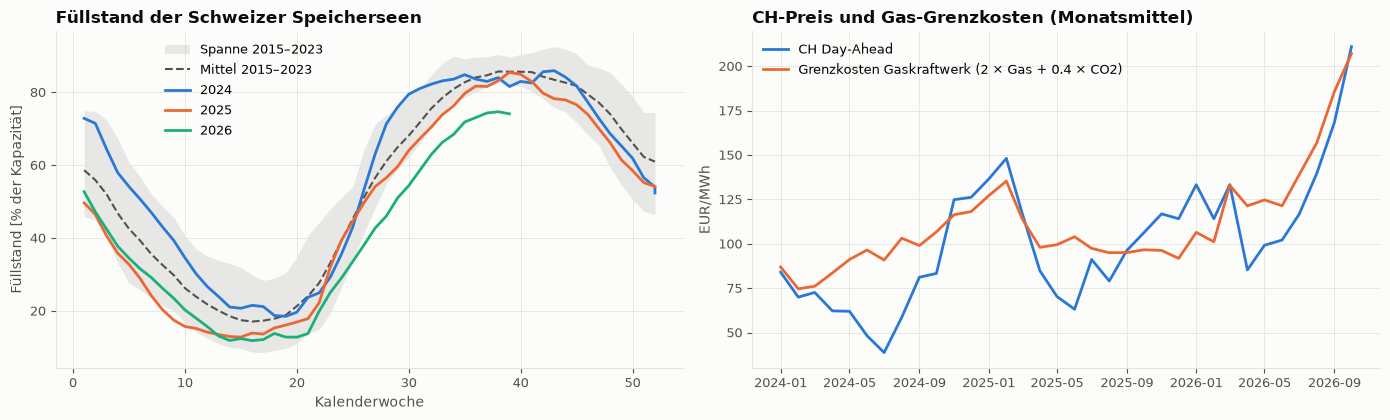

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
st = storage.copy()
st["week"] = dp.storage_week(st.index)
clim = st[st.index.year <= 2023].groupby("week")["Füllstand %"].agg(["mean", "min", "max"])
ax.fill_between(clim.index, clim["min"], clim["max"], color=INK_2, alpha=0.12, linewidth=0, label="Spanne 2015–2023")
ax.plot(clim.index, clim["mean"], color=INK_2, linestyle="--", label="Mittel 2015–2023")
for year, color in zip((2024, 2025, 2026), COLORS):
    s = st[st.index.year == year]
    ax.plot(s["week"], s["Füllstand %"], color=color, linewidth=2, label=str(year))
ax.set_title("Füllstand der Schweizer Speicherseen")
ax.set_xlabel("Kalenderwoche")
ax.set_ylabel("Füllstand [% der Kapazität]")
ax.legend(loc="upper center", bbox_to_anchor=(0.3, 1))

ax = axes[1]
monthly_price = hourly["price_ch"].tz_convert(dp.TZ).resample("MS").mean().tz_localize(None)
f = fuel.copy()
f.index = pd.to_datetime(f.index)
monthly_fuel = f.resample("MS").mean().loc[monthly_price.index.min():monthly_price.index.max()]
ax.plot(monthly_price.index, monthly_price, color=COLORS[0], linewidth=2, label="CH Day-Ahead")
ax.plot(monthly_fuel.index, monthly_fuel["Gaskraftwerk Grenzkosten"], color=COLORS[1], linewidth=2,
        label="Grenzkosten Gaskraftwerk (2 × Gas + 0.4 × CO2)")
ax.set_title("CH-Preis und Gas-Grenzkosten (Monatsmittel)")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left")
save(fig, "01_neue_quellen.png")

**Was wir sehen:**
- Der Füllstand folgt jedes Jahr derselben Kurve: Tiefpunkt im April, Höchststand im September. Der
  Stand allein ist deshalb fast nur ein Kalender. 2024 lag er im Frühjahr deutlich über dem Mittel
  (~+10 Prozentpunkte), ab 2025 darunter. Diese Abweichung wird der Kandidat **Füllstand Anomalie**.
- CH-Preis und Gas-Grenzkosten verlaufen im Monatsmittel parallel. Der Gaspreis erklärt also vor
  allem das **Niveau** über Monate, nicht die Schwankung innerhalb eines Tages.

### 1.2 Wetterprognose für übermorgen

**Problem:** Die Netzbetreiber veröffentlichen ihre Prognosen für PV, Wind und Last jeweils für den
**nächsten** Tag. Die Prognose für D+2 erscheint also erst am Abend von D+1, nach unserem
Prognosezeitpunkt:

```
Tag D,   ~12 Uhr   Auktion → Preise D+1 bekannt → wir prognostizieren D+2
Tag D+1, ~18 Uhr   Netzbetreiber-Prognose für D+2 erscheint   ← zu spät
```

Würde das Modell mit diesen Prognosen trainiert, nutzte es Wissen aus der Zukunft und sähe besser
aus, als es im Einsatz wäre.

**Lösung:** Wetterprognosen reichen mehrere Tage voraus. Sie gehen **direkt** als Prädiktoren ins
Preismodell: Temperatur, Einstrahlung und Wind in 100 m Höhe je Land (CH, DE, FR, IT, AT) als Mittel
mehrerer Punkte. Das Preismodell lernt selbst, dass z. B. viel Wind in Norddeutschland den Preis
drückt.

**Warum archivierte Prognosen und nicht gemessenes Wetter?** Zum Trainieren braucht es die
Prognosen, **wie sie damals vorlagen**, mit ihren Fehlern. Mit gemessenem Wetter kennte das Modell
das Wetter von übermorgen perfekt und würde sich zu stark darauf verlassen. Open-Meteo archiviert,
was ein Wettermodell **2 bzw. 3 Tage vor** dem Zielzeitpunkt vorhergesagt hat. Für jede Stunde von
D+2 wird der Lauf genommen, der am Tag D um 12 Uhr schon publiziert war (frühe Stunden: 2 Tage
vorher, übrige: 3 Tage vorher).

**Warum diese Grafik?** Die Wetterprognose ersetzt die Produktionsprognose der Netzbetreiber. Wir
prüfen, wie gut sie die tatsächliche Produktion trifft, am Beispiel des deutschen Winds (grösster
Einzeltreiber der Preisschwankung).

**Was wir prüfen wollen:** Steigt die Windproduktion mit der prognostizierten Windgeschwindigkeit,
und wie stark streut sie? Folgt die Prognose von übermorgen den grossen Schwankungen einer Woche?

Spearman ρ Windprognose (D+2) ↔ Windproduktion DE: +0.89


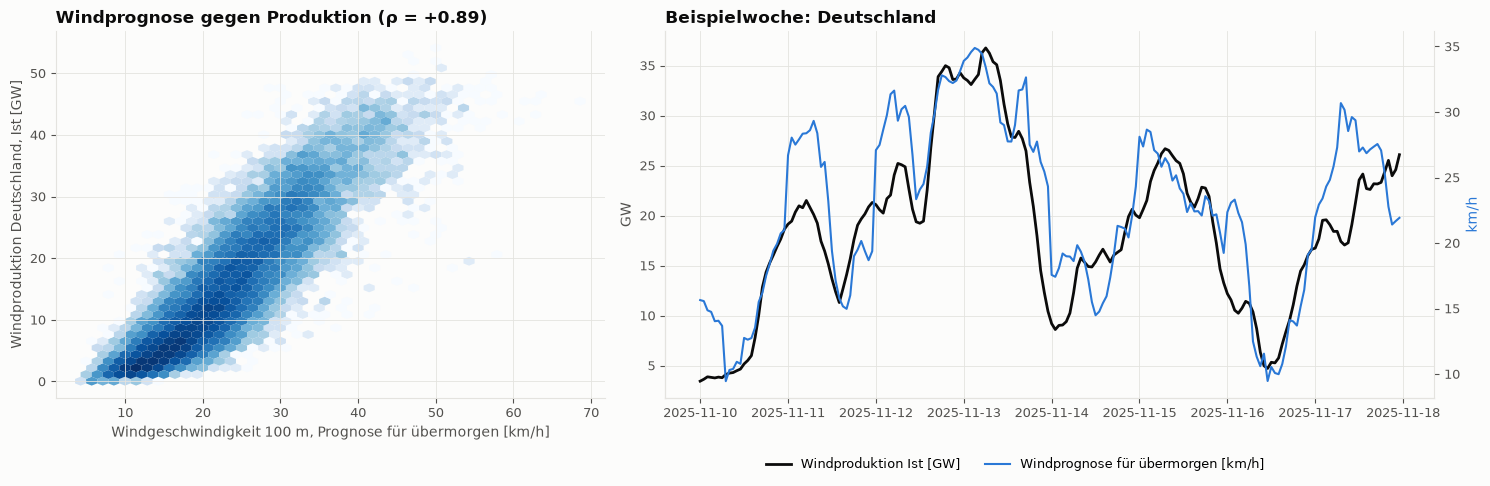

In [4]:
wind_ist = hourly[["act_de_wind_onshore", "act_de_wind_offshore"]].sum(axis=1, min_count=2) / 1000
wind_fc = weather[[f"de_{p}_wind_speed_100m" for p in dp.WEATHER_POINTS["de"]]].mean(axis=1).reindex(wind_ist.index)
d = pd.concat({"Prognose": wind_fc, "Ist": wind_ist}, axis=1).dropna()
rho_wind = d.corr(method="spearman").iloc[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.hexbin(d["Prognose"], d["Ist"], gridsize=45, bins="log", cmap="Blues", mincnt=1, linewidths=0)
ax.set_xlabel("Windgeschwindigkeit 100 m, Prognose für übermorgen [km/h]")
ax.set_ylabel("Windproduktion Deutschland, Ist [GW]")
ax.set_title(f"Windprognose gegen Produktion (ρ = {rho_wind:+.2f})")

ax = axes[1]
week = slice("2025-11-10", "2025-11-17")
ax.plot(wind_ist.loc[week].index, wind_ist.loc[week], color=INK, linewidth=2, label="Windproduktion Ist [GW]")
ax.set_ylabel("GW")
ax2 = ax.twinx()
ax2.plot(wind_fc.loc[week].index, wind_fc.loc[week], color=COLORS[0], label="Windprognose für übermorgen [km/h]")
ax2.set_ylabel("km/h", color=COLORS[0])
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Beispielwoche: Deutschland")
fig.legend(loc="upper center", bbox_to_anchor=(0.68, 0.02), ncol=2)
save(fig, "02_wetterprognose_d2.png")
print(f"Spearman ρ Windprognose (D+2) ↔ Windproduktion DE: {rho_wind:+.2f}")

**Was wir sehen:**
- Die Produktion steigt klar mit der prognostizierten Windgeschwindigkeit (ρ +0.89). Unter ~10 km/h
  bleibt sie nahe null; darüber steigt sie fast gleichmässig an. Die Wetterprognose von übermorgen
  trägt also den grössten Teil der Information, die eine MW-Prognose hätte.
- Die Wolke ist breit: Dieselbe Windgeschwindigkeit führt zu unterschiedlicher Produktion (Prognose-
  fehler zwei Tage vorher, Abschaltungen, Zubau über die Zeit).
- In der Beispielwoche folgt die Prognose den grossen Wechseln zwischen windigen und ruhigen Tagen.
  Genau diese Wechsel bewegen den Preis.

Ein eigenes Zwischenmodell, das aus dem Wetter PV-, Wind- und Lastproduktion in MW schätzt, könnte
diese Umrechnung genauer machen. Das ist als mögliche Erweiterung im README beschrieben.

## 2 Kandidaten-Prädiktoren

`dp.build_candidates` erzeugt alle 46 Kandidaten mit den Verschiebungen der D+2-Situation.
Zusätzlich zur Zielgrösse **Preis CH** wird **Δ Preis CH zu Vortag** (Preis − Preis 24 h vorher)
betrachtet: Ein Modell, das die Änderung gegenüber gestern vorhersagt, braucht andere Prädiktoren
als eines, das das Niveau vorhersagt.

Damit die Lags in den ersten Tagen 2024 nicht leer sind, wird der Dezember 2023 als Vorlauf
mitgeladen (`dp.load_warmup_2023`: Preise CH und Nachbarn, Ist-Erzeugung CH/FR, Handel). Daraus
werden die Lags berechnet; danach wird auf 2024 zugeschnitten.

Die vollständige Tabelle steht danach in der Variable **`candidates`** (eine Zeile je Stunde, Index
UTC, 46 Prädiktoren + 2 Zielgrössen).

In [5]:
warmup = dp.load_warmup_2023()
extended = pd.concat([warmup, hourly]).sort_index()
candidates_raw = dp.build_candidates(extended, storage, fuel, weather).loc[dp.START:]
print(f"{candidates_raw.shape[1] - 2} Kandidaten, {len(candidates_raw):,} Stunden "
      f"({candidates_raw.index.min():%Y-%m-%d} – {candidates_raw.index.max():%Y-%m-%d})")

46 Kandidaten, 24,648 Stunden (2024-01-01 – 2026-10-23)


### 2.1 Was jeder Prädiktor ist

**Tabelle: alle 46 Kandidaten**, auch die später weggelassenen. *Typ* sagt, welche Werte möglich
sind: **stetig** = beliebige Zahl mit Einheit, **binär** = nur 0 oder 1, **zyklisch** = Sinus/Kosinus
zwischen −1 und 1, **Prozent/Prozentpunkte** = Anteil bzw. Abweichung davon. *Verfügbar als* sagt,
mit welcher Verzögerung der Wert zum Prognosezeitpunkt (Tag D, 12 Uhr) bekannt ist. *Entscheid*
fasst das Ergebnis der Abschnitte 3–6 zusammen.

**Warum Sinus und Kosinus?** Als Zahl 0–23 lägen 23 Uhr und 0 Uhr weit auseinander, obwohl sie
benachbart sind. Auf einem Kreis (Sinus und Kosinus zusammen) liegen sie nebeneinander; dasselbe
gilt für Dezember und Januar.

In [6]:
dp.predictor_table().style.set_properties(subset=["Erklärung"], **{"text-align": "left", "white-space": "normal"})

,Gruppe,Typ,Einheit,Erklärung,verfügbar als,Entscheid
Prädiktor,,,,,,
CH Lag 24h,Preis CH (Lags),stetig,EUR/MWh,"CH-Preis derselben Stunde am Vortag (D+1, schon bekannt)",Lag 24 h,behalten
CH Lag 48h,Preis CH (Lags),stetig,EUR/MWh,CH-Preis derselben Stunde zwei Tage vorher,Lag 48 h,weglassen
CH Lag 168h,Preis CH (Lags),stetig,EUR/MWh,CH-Preis derselben Stunde eine Woche vorher (gleicher Wochentag),Lag 168 h,behalten
CH Mittel Vortag,Preis CH (Lags),stetig,EUR/MWh,Tagesmittel des CH-Preises am Vortag,Tag D+1,weglassen
CH Mittel 7 Tage,Preis CH (Lags),stetig,EUR/MWh,Mittel der Tagesmittel der letzten 7 Tage: aktuelles Preisniveau,bis D+1,behalten
DE Lag 24h,Nachbarpreise (Lag 24h),stetig,EUR/MWh,Preis Deutschland/Luxemburg derselben Stunde am Vortag,Lag 24 h,im Modell testen
FR Lag 24h,Nachbarpreise (Lag 24h),stetig,EUR/MWh,Preis Frankreich derselben Stunde am Vortag,Lag 24 h,im Modell testen
IT-Nord Lag 24h,Nachbarpreise (Lag 24h),stetig,EUR/MWh,Preis Norditalien derselben Stunde am Vortag,Lag 24 h,weglassen
AT Lag 24h,Nachbarpreise (Lag 24h),stetig,EUR/MWh,Preis Österreich derselben Stunde am Vortag,Lag 24 h,weglassen


### 2.2 Fehlende Werte füllen

Nach dem Vorlauf aus 2023 fehlen nur noch wenige Werte: einzelne Stunden in den Quellen (z. B. an
der Zeitumstellung) und ein langer Block in den Wetterprognosen. `dp.fill_gaps` füllt jede Lücke mit dem
Wert **derselben Stunde am Vortag**, und wo dieser fehlt, **der Vorwoche**. Das passt zur
Tages- und Wochenstruktur des Strommarkts (Autokorrelation, EDA 5.4).

Gefüllt werden nur Lücken bis 7 Tage am Stück. **Nicht füllbar** ist der Block vom 1.1. bis
17.2.2024 in den Wetterprognosen: Open-Meteo hat Prognosen von
zwei Tagen vorher erst ab dem 20.1.2024 (Wind in 100 m ab dem 18.2.2024), und für 2023 gibt es sie
gar nicht. Ein Vortageswert wäre dort erfunden. Für die Modellierung beginnt der Datensatz deshalb
am **18.2.2024**; XGBoost könnte mit leeren Werten zwar umgehen, würde in diesen Wochen aber ohne
Wetterinformation lernen.

In [7]:
candidates, gap_report = dp.fill_gaps(candidates_raw)
gap_report.sort_values("fehlend", ascending=False)

,fehlend,Vortag,Vorwoche,bleibt leer
Prädiktor,,,,
Wind 100m DE (D+2),1151,0,0,1151
Wind 100m IT (D+2),1151,0,0,1151
Wind 100m AT (D+2),1151,0,0,1151
Wind 100m CH (D+2),1151,0,0,1151
Wind 100m FR (D+2),1151,0,0,1151
Niederschlag 7 Tage CH,508,0,0,508
Einstrahlung AT (D+2),485,0,0,485
Temperatur CH (D+2),485,0,0,485
Einstrahlung CH (D+2),485,0,0,485


### 2.3 Datensatz für die Modellierung

`candidates` wird als CSV gespeichert und steht so für `03_modeling.ipynb` bereit, ohne die
Downloads erneut auszuführen. Die Datei liegt unter `data/` und ist deshalb
nicht versioniert; sie entsteht bei jedem Lauf dieses Notebooks neu.

In [8]:
dp.DATASET_CSV.parent.mkdir(parents=True, exist_ok=True)
candidates.rename_axis("time_utc").to_csv(dp.DATASET_CSV)
print(f"{dp.DATASET_CSV.relative_to(ROOT)}: {candidates.shape[0]:,} Stunden × {candidates.shape[1]} Spalten")
overview = pd.DataFrame({
    "Gruppe": [dp.GROUP_OF[c] for c in candidates],
    "Abdeckung vorher": candidates_raw.notna().mean(),
    "Abdeckung nachher": candidates.notna().mean(),
    "Median": candidates.median(),
}).rename_axis("Kandidat")
overview.style.format({"Abdeckung vorher": "{:.1%}", "Abdeckung nachher": "{:.1%}", "Median": "{:,.1f}"})

data/processed/candidates_d2.csv: 24,648 Stunden × 48 Spalten


,Gruppe,Abdeckung vorher,Abdeckung nachher,Median
Kandidat,,,,
Preis CH,Ziel,100.0%,100.0%,101.8
Δ Preis CH zu Vortag,Ziel,100.0%,100.0%,-0.5
CH Lag 24h,Preis CH (Lags),100.0%,100.0%,101.6
CH Lag 48h,Preis CH (Lags),100.0%,100.0%,101.5
CH Lag 168h,Preis CH (Lags),100.0%,100.0%,101.0
CH Mittel Vortag,Preis CH (Lags),100.0%,100.0%,99.3
CH Mittel 7 Tage,Preis CH (Lags),100.0%,100.0%,98.0
DE Lag 24h,Nachbarpreise (Lag 24h),100.0%,100.0%,92.1
FR Lag 24h,Nachbarpreise (Lag 24h),100.0%,100.0%,65.0


## 3 Multikorrelationsmatrix

**Warum diese Grafik?** 46 Kandidaten sind zu viele, und viele messen vermutlich dasselbe (z. B.
die Preise der Nachbarländer oder die Temperatur in fünf Ländern). Die Matrix vergleicht **jeden
Kandidaten mit jedem anderen**.

**Was wir erkennen wollen:** dunkle Blöcke abseits der Diagonale. Sie zeigen Gruppen, die fast
dieselbe Information tragen; von jeder Gruppe genügt ein Vertreter. Die beiden obersten Zeilen
(Zielgrössen) zeigen zusätzlich einen ersten Eindruck der Relevanz.

**Lesart:** Spearman-Rangkorrelation ρ. Blau = gleichgerichtet, rot = gegenläufig, je kräftiger desto
stärker; Werte ab |ρ| ≥ 0.7 sind beschriftet. Die farbigen Balken am Rand markieren die Gruppen.
Spearman statt Pearson, weil die Preisverteilung dicke Ränder hat (EDA 3.2) und Spearman nur die
Rangfolge nutzt: Einzelne Extrempreise (−464 EUR/MWh) verzerren das Ergebnis nicht, und auch
monotone, aber gekrümmte Zusammenhänge (Windkurve) zählen voll.

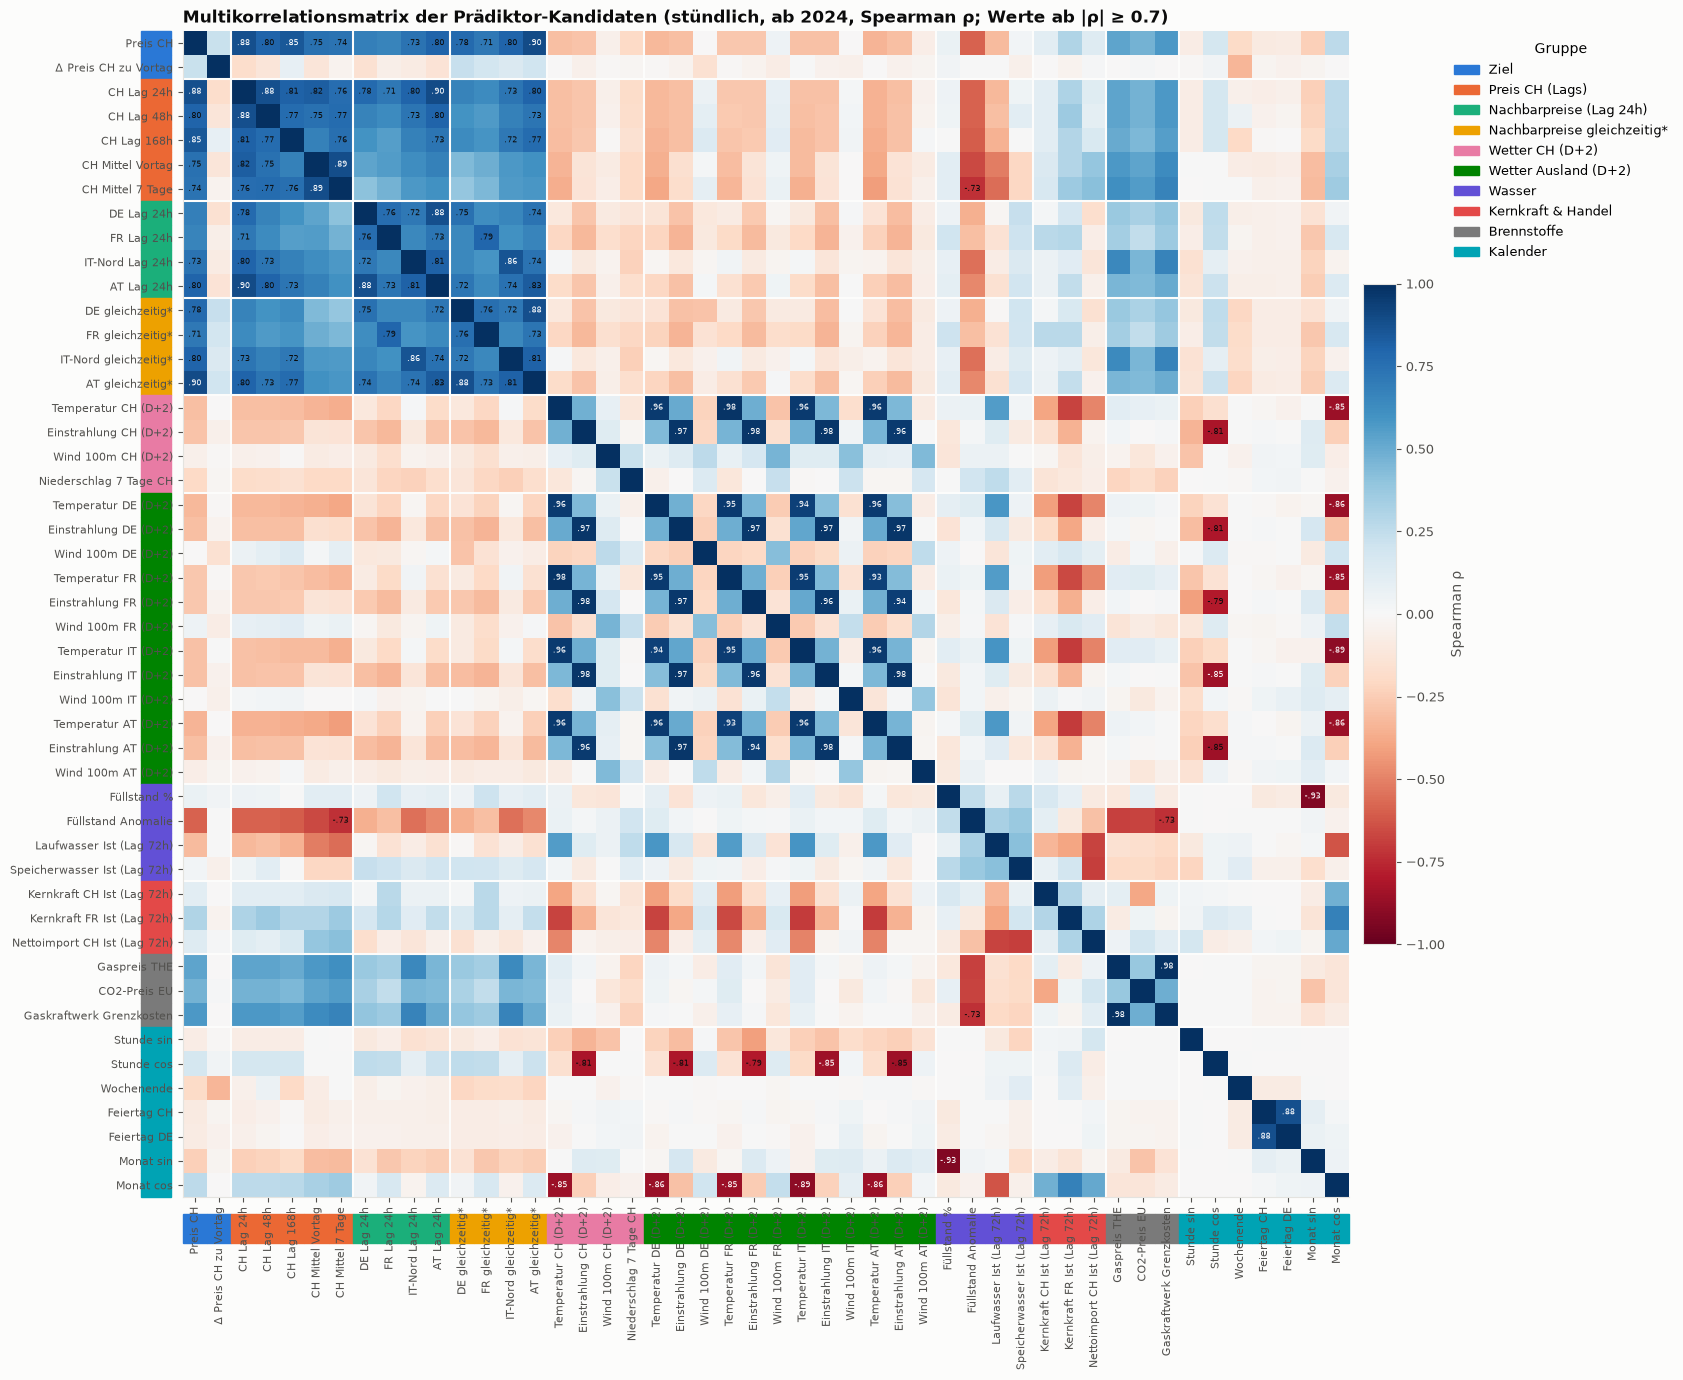

In [9]:
corr = candidates.corr(method="spearman")
cols = list(corr.columns)
n = len(cols)
fig, ax = plt.subplots(figsize=(17, 15))
im = ax.imshow(corr.to_numpy(), cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(n), cols, rotation=90, fontsize=8)
ax.set_yticks(range(n), cols, fontsize=8)
ax.grid(False)
# Gruppengrenzen und Farbbalken
edges = np.cumsum([len(v) for v in dp.GROUPS.values()])[:-1] - 0.5
for e in edges:
    ax.axhline(e, color=SURFACE, linewidth=1.5)
    ax.axvline(e, color=SURFACE, linewidth=1.5)
for i, c in enumerate(cols):
    color = GROUP_COLOR[dp.GROUP_OF[c]]
    ax.add_patch(plt.Rectangle((-2.2, i - 0.5), 1.2, 1, color=color, clip_on=False))
    ax.add_patch(plt.Rectangle((i - 0.5, n + 0.2), 1, 1.2, color=color, clip_on=False))
# Werte nur für starke Zusammenhänge beschriften (sonst unlesbar)
for i in range(n):
    for j in range(n):
        v = corr.iat[i, j]
        if i != j and abs(v) >= 0.7:
            ax.text(j, i, f"{v:.2f}".replace("0.", "."), ha="center", va="center", fontsize=5.5,
                    color="white" if abs(v) > 0.85 else INK)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in dp.GROUPS]
ax.legend(handles, dp.GROUPS, loc="upper left", bbox_to_anchor=(1.08, 1), title="Gruppe", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.5, pad=0.01, label="Spearman ρ")
ax.set_title("Multikorrelationsmatrix der Prädiktor-Kandidaten (stündlich, ab 2024, Spearman ρ; Werte ab |ρ| ≥ 0.7)")
save(fig, "03_multikorrelation.png")

**Was wir sehen:**
- **Preis-Lags und Nachbarpreise** bilden einen grossen Block (ρ 0.8–0.9): Der Strommarkt ist
  gekoppelt, die Nachbarpreise von gestern sagen fast dasselbe wie der CH-Preis von gestern.
- **Temperatur und Einstrahlung** sind über alle fünf Länder fast identisch (ρ 0.93–0.98): Das Wetter
  in Mitteleuropa ist grossräumig. Eine Messreihe je Grösse genügt.
- **Wind** dagegen unterscheidet sich je Land deutlich (ρ 0.1–0.5): Nordseewind in Deutschland ist
  ein anderes Signal als Alpenwind.
- Gaspreis und Gas-Grenzkosten sind fast gleich (ρ 0.98), ebenso Füllstand % und Monat (ρ −0.93).

## 4 Relevanz für die Zielgrösse

**Warum diese Grafik?** Die Matrix zeigt Redundanz, aber nicht übersichtlich, welcher Kandidat
überhaupt etwas mit dem Preis zu tun hat. Hier wird jeder Kandidat einzeln gegen die Zielgrössen
gestellt.

**Was wir erkennen wollen:** Welche Kandidaten hängen mit dem **Preisniveau** zusammen, welche mit
der **Änderung zum Vortag**, und welche mit keinem von beiden?

- **Spearman ρ mit dem Preis:** monotoner Zusammenhang mit dem Preisniveau.
- **Spearman ρ mit Δ Preis:** Zusammenhang mit der Änderung zum Vortag.
- **Mutual Information mit dem Preis:** erfasst auch nicht-monotone Zusammenhänge
  (z. B. Tageszeit). Sie hat keine feste Obergrenze; verglichen werden nur die Grössen untereinander.

**Vorsicht bei langsamen Grössen:** Füllstand, Gas-/CO2-Preis, 7-Tage-Mittel und die Ist-Kernkraft
ändern sich nur täglich oder wöchentlich. Über nur 2.8 Jahre wirken sie fast wie ein Datumsstempel:
Sie „wissen“, in welcher Phase man ist, und damit das damalige Preisniveau. Mutual Information und
teils auch ρ überschätzen sie deshalb. Ob sie wirklich helfen, zeigt erst ein zeitlich getrennter
Test im Modell.

,ρ Preis,ρ Δ Preis,MI Preis,Gruppe
AT gleichzeitig*,+0.90,+0.20,1.15,Nachbarpreise gleichzeitig*
CH Lag 24h,+0.88,-0.17,0.95,Preis CH (Lags)
CH Lag 168h,+0.85,+0.09,0.76,Preis CH (Lags)
CH Lag 48h,+0.80,-0.12,0.67,Preis CH (Lags)
AT Lag 24h,+0.80,-0.14,0.65,Nachbarpreise (Lag 24h)
IT-Nord gleichzeitig*,+0.80,+0.14,0.83,Nachbarpreise gleichzeitig*
DE gleichzeitig*,+0.78,+0.23,0.87,Nachbarpreise gleichzeitig*
CH Mittel Vortag,+0.75,-0.12,0.64,Preis CH (Lags)
CH Mittel 7 Tage,+0.74,-0.03,0.66,Preis CH (Lags)
IT-Nord Lag 24h,+0.73,-0.08,0.59,Nachbarpreise (Lag 24h)


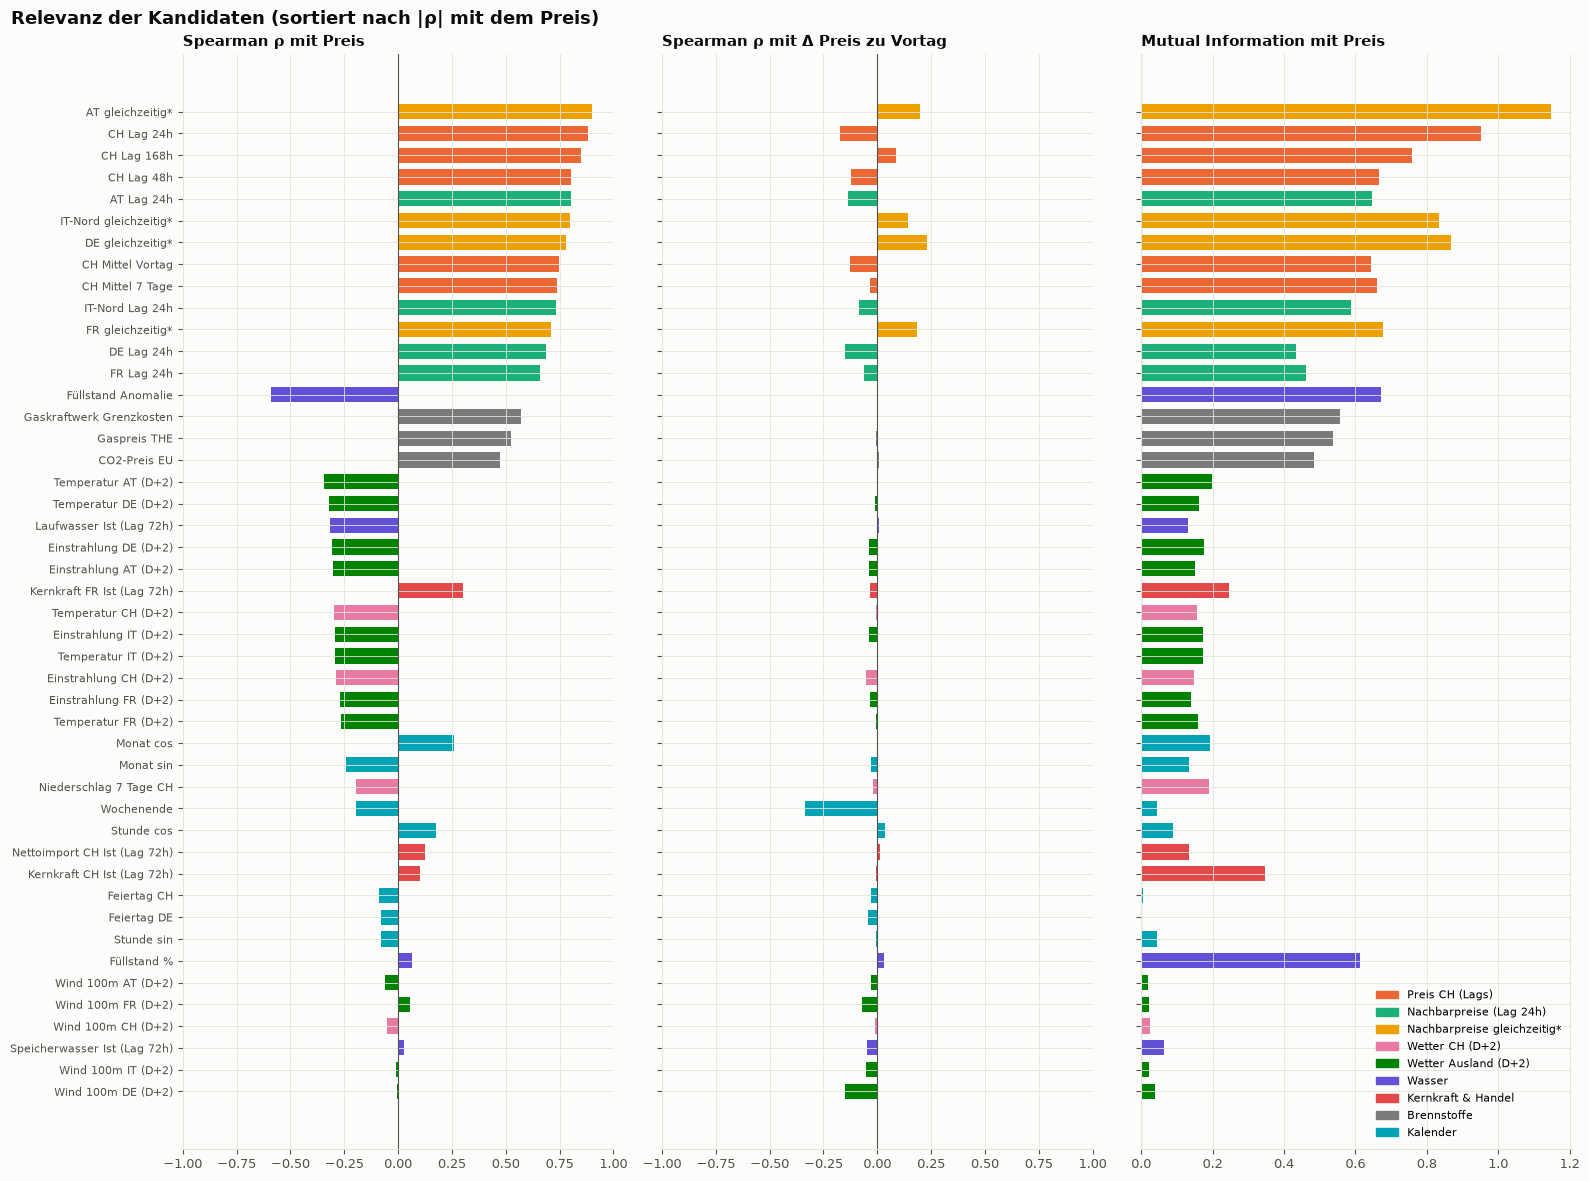

In [10]:
feats = [c for c in candidates if dp.GROUP_OF[c] != "Ziel"]
sample = candidates.dropna().sample(n=min(12_000, len(candidates.dropna())), random_state=0)
mi = pd.Series(mutual_info_regression(sample[feats], sample[dp.TARGET], random_state=0), index=feats)
relevance = pd.DataFrame({
    "ρ Preis": corr.loc[feats, dp.TARGET],
    "ρ Δ Preis": corr.loc[feats, dp.TARGET_DELTA],
    "MI Preis": mi,
    "Gruppe": [dp.GROUP_OF[c] for c in feats],
}).sort_values("ρ Preis", key=np.abs)

fig, axes = plt.subplots(1, 3, figsize=(16, 12), sharey=True)
colors = [GROUP_COLOR[g] for g in relevance["Gruppe"]]
for ax, col, title in zip(axes, ["ρ Preis", "ρ Δ Preis", "MI Preis"],
                          ["Spearman ρ mit Preis", "Spearman ρ mit Δ Preis zu Vortag", "Mutual Information mit Preis"]):
    ax.barh(relevance.index, relevance[col], color=colors, height=0.7)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="y", labelsize=8)
axes[0].set_xlim(-1, 1)
axes[1].set_xlim(-1, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in dp.GROUPS if g != "Ziel"]
axes[2].legend(handles, [g for g in dp.GROUPS if g != "Ziel"], loc="lower right", fontsize=8)
fig.suptitle("Relevanz der Kandidaten (sortiert nach |ρ| mit dem Preis)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
save(fig, "04_relevanz.png")
relevance.sort_values("ρ Preis", key=np.abs, ascending=False).style.format(
    {"ρ Preis": "{:+.2f}", "ρ Δ Preis": "{:+.2f}", "MI Preis": "{:.2f}"}).bar(
    subset=["MI Preis"], color="#c8daf2")

**Was wir sehen:**
- **Preisniveau:** Am stärksten sind die Preise von gestern und letzter Woche (ρ 0.85–0.88), dann
  Füllstand-Anomalie (−0.59) und Gas-Grenzkosten (+0.57). Temperatur und Einstrahlung wirken
  gegenläufig (ρ ≈ −0.3): warm und sonnig → mehr PV, weniger Heizen → billiger.
- **Änderung zum Vortag:** Fast alles ist hier schwach. Die klarsten Signale sind Wochenende
  (−0.34) und Wind Deutschland (−0.15): Mehr Wind als gestern macht den Strom billiger.
- **Kein Zusammenhang:** Wind CH, IT und AT, Speicherwasser und Füllstand % (|ρ| ≤ 0.06).
- Die Nachbarpreise *gleichzeitig* sind am stärksten (AT ρ 0.90), aber für übermorgen nicht bekannt.

## 5 Redundanz

### 5.1 Stark korrelierte Paare (|ρ| ≥ 0.9)
Bei solchen Paaren trägt der zweite Prädiktor kaum zusätzliche Information. Baummodelle stürzen
dadurch nicht ab, aber die Wichtigkeit verteilt sich zufällig auf beide, was die Erklärung (SHAP)
erschwert.

In [11]:
dp.redundant_pairs(corr, 0.9)

,Prädiktor A,Prädiktor B,ρ
0,Gaspreis THE,Gaskraftwerk Grenzkosten,0.98
1,Temperatur CH (D+2),Temperatur FR (D+2),0.98
2,Einstrahlung IT (D+2),Einstrahlung AT (D+2),0.98
3,Einstrahlung CH (D+2),Einstrahlung FR (D+2),0.98
4,Einstrahlung CH (D+2),Einstrahlung IT (D+2),0.98
5,Einstrahlung CH (D+2),Einstrahlung DE (D+2),0.97
6,Einstrahlung DE (D+2),Einstrahlung IT (D+2),0.97
7,Einstrahlung DE (D+2),Einstrahlung AT (D+2),0.97
8,Einstrahlung DE (D+2),Einstrahlung FR (D+2),0.97
9,Einstrahlung FR (D+2),Einstrahlung IT (D+2),0.96


### 5.2 Cluster und Vorschlag je Cluster

Hierarchisches Clustering mit dem Abstand 1 − |ρ|: Prädiktoren mit |ρ| ≥ 0.8 landen im selben
Cluster. Je Cluster wird der Kandidat mit der höchsten Mutual Information als **Vertreter**
vorgeschlagen. Einzelne Cluster mit nur einem Mitglied sind nicht redundant.

In [12]:
clusters = dp.cluster_shortlist(corr, relevance["MI Preis"], threshold=0.2)
multi = clusters[clusters.groupby("Cluster")["Cluster"].transform("size") > 1]
multi.style.format({"Relevanz": "{:.2f}"}).apply(
    lambda r: ["font-weight: bold" if r["Vertreter"] else "" for _ in r], axis=1)

,Cluster,Gruppe,Relevanz,Vertreter
Füllstand %,7,Wasser,0.61,True
Monat sin,7,Kalender,0.13,False
CH Mittel 7 Tage,8,Preis CH (Lags),0.66,True
CH Mittel Vortag,8,Preis CH (Lags),0.64,False
AT gleichzeitig*,12,Nachbarpreise gleichzeitig*,1.15,True
DE gleichzeitig*,12,Nachbarpreise gleichzeitig*,0.87,False
IT-Nord gleichzeitig*,13,Nachbarpreise gleichzeitig*,0.83,True
IT-Nord Lag 24h,13,Nachbarpreise (Lag 24h),0.59,False
CH Lag 24h,14,Preis CH (Lags),0.95,True
CH Lag 48h,14,Preis CH (Lags),0.67,False


### 5.3 Warum diese Kandidaten wegfallen

**Warum diese Grafik?** Die Zahlen in den Tabellen oben sagen, *dass* ein Kandidat wegfällt. Die
Grafik zeigt für jeden einzeln, *warum*, damit der Entscheid nachvollziehbar ist.

**Was wir erkennen wollen:**
- **Redundant** (blau): Kandidat gegen den behaltenen Vertreter. Liegen die Punkte auf einer
  schmalen Diagonale, misst der Kandidat dasselbe und bringt keine neue Information.
- **Kein Zusammenhang** (rot): Kandidat gegen den CH-Preis. Eine formlose Wolke mit ρ ≈ 0 heisst,
  dass der Preis bei hohen und tiefen Werten gleich verteilt ist.
- **Wind je Land** (Balken): ρ mit Preis und mit der Änderung zum Vortag, um zu zeigen, welcher Wind
  bleibt.
- **Feiertag DE:** als Tabelle, weil beide Grössen nur 0 oder 1 sind.

Dunkle Flächen = viele Stunden. Die Achsen zeigen P0.5–P99.5; extreme Preise bleiben in ρ enthalten.
Temperatur und Einstrahlung der vier Nachbarländer stehen gemeinsam in je einem Feld.

,Vergleich mit,ρ mit Preis,ρ mit Δ Preis,ρ mit Vergleich
CH Lag 48h,CH Lag 24h,+0.80,-0.12,+0.88
AT Lag 24h,CH Lag 24h,+0.80,-0.14,+0.90
IT-Nord Lag 24h,CH Lag 24h,+0.73,-0.08,+0.80
CH Mittel Vortag,CH Mittel 7 Tage,+0.75,-0.12,+0.89
Gaspreis THE,Gaskraftwerk Grenzkosten,+0.53,-0.01,+0.98
Temperatur DE (D+2),Temperatur CH (D+2),-0.32,-0.01,+0.96
Temperatur FR (D+2),Temperatur CH (D+2),-0.27,-0.01,+0.98
Temperatur IT (D+2),Temperatur CH (D+2),-0.29,+0.00,+0.96
Temperatur AT (D+2),Temperatur CH (D+2),-0.34,-0.00,+0.96
Einstrahlung DE (D+2),Einstrahlung CH (D+2),-0.30,-0.04,+0.97


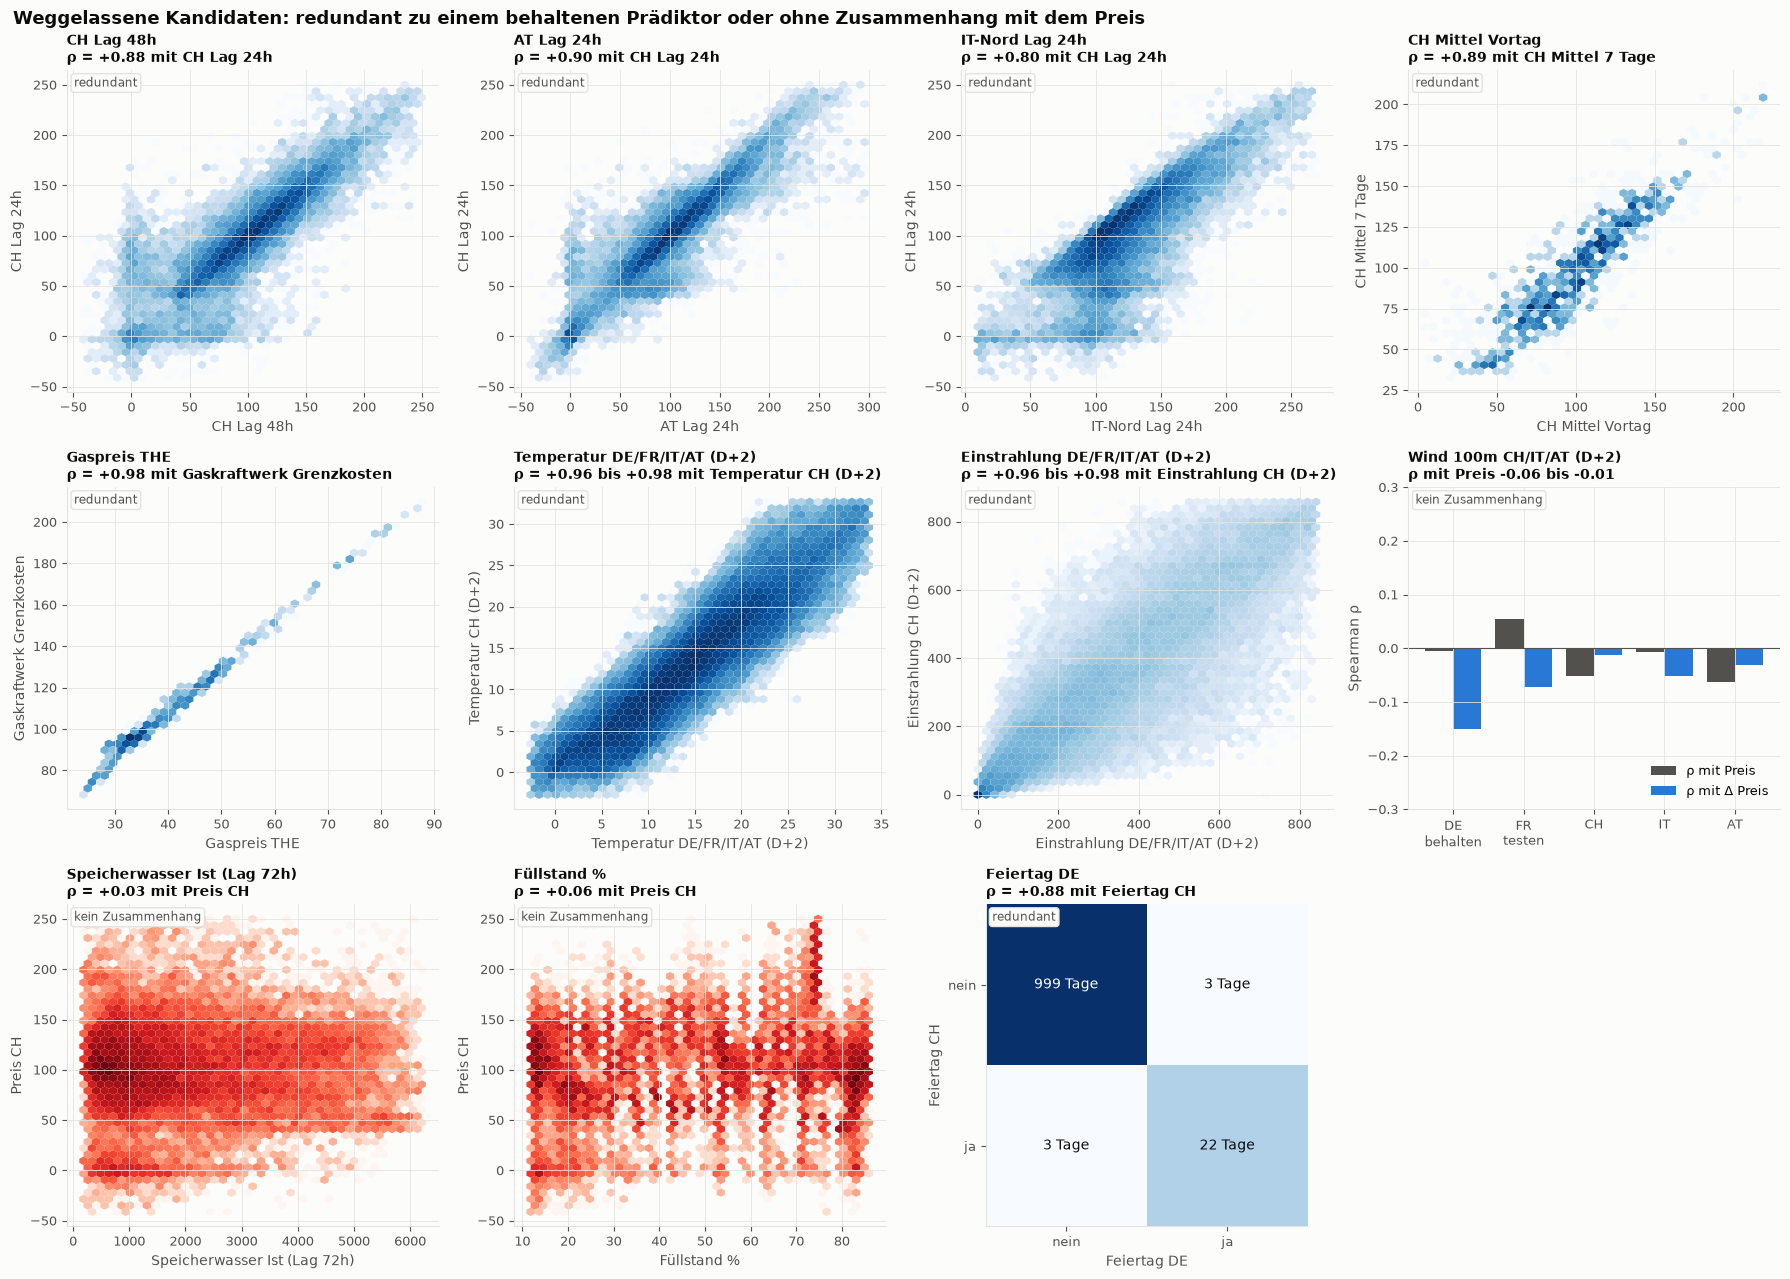

In [13]:
FOREIGN = ("DE", "FR", "IT", "AT")
DROP_PANELS = {  # Titel: (Kandidaten, Vergleichsgrösse, Art)
    "CH Lag 48h": (["CH Lag 48h"], "CH Lag 24h", "redundant"),
    "AT Lag 24h": (["AT Lag 24h"], "CH Lag 24h", "redundant"),
    "IT-Nord Lag 24h": (["IT-Nord Lag 24h"], "CH Lag 24h", "redundant"),
    "CH Mittel Vortag": (["CH Mittel Vortag"], "CH Mittel 7 Tage", "redundant"),
    "Gaspreis THE": (["Gaspreis THE"], "Gaskraftwerk Grenzkosten", "redundant"),
    "Temperatur DE/FR/IT/AT (D+2)": ([f"Temperatur {c} (D+2)" for c in FOREIGN], "Temperatur CH (D+2)", "redundant"),
    "Einstrahlung DE/FR/IT/AT (D+2)": ([f"Einstrahlung {c} (D+2)" for c in FOREIGN], "Einstrahlung CH (D+2)", "redundant"),
    "Wind 100m CH/IT/AT (D+2)": ([f"Wind 100m {c} (D+2)" for c in ("CH", "IT", "AT")], dp.TARGET, "Wind je Land"),
    "Speicherwasser Ist (Lag 72h)": (["Speicherwasser Ist (Lag 72h)"], dp.TARGET, "kein Zusammenhang"),
    "Füllstand %": (["Füllstand %"], dp.TARGET, "kein Zusammenhang"),
    "Feiertag DE": (["Feiertag DE"], "Feiertag CH", "redundant"),
}
KIND_COLOR = {"redundant": "Blues", "kein Zusammenhang": "Reds"}


def tag(ax, text):
    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top", fontsize=8.5, color=INK_2,
            bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec=GRID))


fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, (title, (feats_, ref, kind)) in zip(axes.flat, DROP_PANELS.items()):
    rhos = [corr.loc[f, ref] for f in feats_]
    rho_txt = f"{rhos[0]:+.2f}" if len(rhos) == 1 else f"{min(rhos):+.2f} bis {max(rhos):+.2f}"
    if kind == "Wind je Land":
        winds = [f"Wind 100m {c} (D+2)" for c in ("DE", "FR", "CH", "IT", "AT")]
        labels = ["DE\nbehalten", "FR\ntesten", "CH", "IT", "AT"]
        x = np.arange(len(winds))
        ax.bar(x - 0.2, corr.loc[winds, dp.TARGET], width=0.4, color=INK_2, label="ρ mit Preis")
        ax.bar(x + 0.2, corr.loc[winds, dp.TARGET_DELTA], width=0.4, color=COLORS[0], label="ρ mit Δ Preis")
        ax.axhline(0, color=INK_2, linewidth=0.8)
        ax.set_xticks(x, labels)
        ax.set_ylim(-0.3, 0.3)
        ax.set_ylabel("Spearman ρ")
        ax.legend(loc="lower right")
        ax.set_title(f"{title}\nρ mit Preis {rho_txt}", fontsize=10)
        tag(ax, "kein Zusammenhang")
        continue
    d = pd.concat([candidates[[f, ref]].set_axis(["x", "y"], axis=1) for f in feats_]).dropna()
    if d["x"].nunique() <= 2:  # binär: Kreuztabelle
        tab = pd.crosstab(d["y"].map({0: "nein", 1: "ja"}), d["x"].map({0: "nein", 1: "ja"})) / 24
        tab = tab.loc[["nein", "ja"], ["nein", "ja"]]
        ax.imshow(np.log1p(tab.to_numpy()), cmap=KIND_COLOR[kind])
        for (i, j), v in np.ndenumerate(tab.to_numpy()):
            ax.text(j, i, f"{v:,.0f} Tage", ha="center", va="center", fontsize=10,
                    color="white" if v > 100 else INK)
        ax.set_xticks([0, 1], tab.columns)
        ax.set_yticks([0, 1], tab.index)
        ax.grid(False)
    else:
        lo, hi = d.quantile(0.005), d.quantile(0.995)
        d = d[(d >= lo).all(axis=1) & (d <= hi).all(axis=1)]
        ax.hexbin(d["x"], d["y"], gridsize=40, bins="log", cmap=KIND_COLOR[kind], mincnt=1, linewidths=0)
    ax.set_xlabel(title)
    ax.set_ylabel(ref)
    ax.set_title(f"{title}\nρ = {rho_txt} mit {ref}", fontsize=10)
    tag(ax, kind)
for ax in axes.flat[len(DROP_PANELS):]:
    ax.axis("off")
fig.suptitle("Weggelassene Kandidaten: redundant zu einem behaltenen Prädiktor oder ohne Zusammenhang mit dem Preis",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
save(fig, "05_weggelassene_praediktoren.png")
pd.DataFrame({"Vergleich mit": {f: (dp.TARGET if f in dp.GROUPS["Wetter CH (D+2)"] + dp.GROUPS["Wetter Ausland (D+2)"]
                                    and "Wind" in f else r) for _, (fs, r, _) in DROP_PANELS.items() for f in fs},
              "ρ mit Preis": {f: corr.loc[f, dp.TARGET] for fs, _, _ in DROP_PANELS.values() for f in fs},
              "ρ mit Δ Preis": {f: corr.loc[f, dp.TARGET_DELTA] for fs, _, _ in DROP_PANELS.values() for f in fs},
              "ρ mit Vergleich": {f: corr.loc[f, r] for fs, r, _ in DROP_PANELS.values() for f in fs},
              }).style.format({"ρ mit Preis": "{:+.2f}", "ρ mit Δ Preis": "{:+.2f}", "ρ mit Vergleich": "{:+.2f}"})

**Was wir sehen:**
- **Preise:** CH Lag 48h, AT und IT-Nord von gestern liegen eng um die Diagonale mit CH Lag 24h
  (ρ 0.80–0.90). CH Mittel Vortag liegt eng an CH Mittel 7 Tage (ρ 0.89).
- **Gaspreis THE** liegt fast exakt auf einer Linie mit den Gas-Grenzkosten (ρ 0.98), weil diese aus
  2 × Gaspreis + 0.4 × CO2-Preis berechnet werden und der Gasanteil dominiert.
- **Temperatur und Einstrahlung im Ausland** liegen auf der Diagonale mit der Schweiz (ρ 0.96–0.98).
  Das Wetter ist grossräumig; die CH-Reihe vertritt alle.
- **Wind je Land:** Nur der deutsche Wind hängt mit der Preisänderung zusammen (ρ −0.15), der
  französische schwach (−0.07). Wind in CH, IT und AT zeigt bei beiden |ρ| ≤ 0.06; dort gibt es
  kaum Windkraft (CH im Mittel ~18 MW).
- **Speicherwasser Ist** und **Füllstand %:** formlose Wolken (ρ ≤ 0.06). Speicherwasser wird
  gerade dann produziert, wenn der Preis hoch ist; drei Tage alt sagt es nichts über übermorgen.
  Füllstand % ist reine Jahreszeit (ρ −0.93 mit Monat); die Anomalie bleibt.
- **Feiertag DE:** An 22 von 28 Tagen ist auch in der Schweiz Feiertag; die übrigen sind kaum
  preisrelevant.

## 6 Fazit: Vorschlag für die Prädiktoren

| Entscheid | Prädiktoren | Begründung |
|---|---|---|
| **behalten** | CH Lag 24h, CH Lag 168h, CH Mittel 7 Tage | stärkste verfügbare Signale (ρ 0.74–0.88); Lag 168h bringt das Wochenmuster (Autokorrelation, EDA 5.4) |
| **behalten** | Temperatur CH, Einstrahlung CH (D+2) | Wetterprognose für übermorgen; ρ ≈ −0.3 mit dem Preis. Vertreter für Temperatur und Einstrahlung aller Nachbarländer (ρ 0.93–0.98) |
| **behalten** | Wind 100m DE (D+2) | kaum Zusammenhang mit dem Niveau, aber mit der Änderung (ρ −0.15): mehr Wind als gestern → billiger |
| **behalten** | Gaskraftwerk Grenzkosten | ρ 0.57; erklärt das Preisniveau. Ersetzt den Gaspreis (ρ 0.98 untereinander) |
| **behalten** | Füllstand Anomalie | ρ −0.59: weniger Wasser als üblich → höhere Preise. Wegen der kurzen Zeitreihe im Modell prüfen |
| **behalten** | Stunde, Wochenende, Feiertag CH, Monat | nicht monoton, aber zentral für die Tagesform; Wochenende ist das stärkste Signal für Δ Preis (ρ −0.34) |
| **weglassen** (5.3) | CH Lag 48h, AT Lag 24h, IT-Nord Lag 24h, CH Mittel Vortag | fast dieselbe Information wie CH Lag 24h bzw. CH Mittel 7 Tage (ρ 0.80–0.90) |
| **weglassen** (5.3) | Gaspreis THE, Feiertag DE | redundant zu einem behaltenen Prädiktor (ρ 0.88–0.98) |
| **weglassen** (5.3) | Temperatur und Einstrahlung DE, FR, IT, AT (D+2) | grossräumiges Wetter, fast identisch mit der Schweiz (ρ 0.93–0.98) |
| **weglassen** (5.3) | Wind 100m CH, IT, AT (D+2) | kein Zusammenhang mit Preis oder Änderung (|ρ| ≤ 0.06); kaum Windkraft |
| **weglassen** (5.3) | Füllstand %, Speicherwasser Ist | kein Zusammenhang mit dem Preis (ρ ≤ 0.06); Füllstand % ist reine Saison (ρ −0.93 mit Monat) |
| **nicht verfügbar** | Nachbarpreise gleichzeitig* | stärkster Zusammenhang (AT ρ 0.90), aber für D+2 unbekannt. Sie zu prognostizieren wäre dieselbe Aufgabe wie der CH-Preis |
| **im Modell testen** | DE Lag 24h, FR Lag 24h, Wind 100m FR (D+2), CO2-Preis, Kernkraft CH/FR, Laufwasser, Nettoimport, Niederschlag 7 Tage | schwache oder langsame Signale; nur behalten, wenn sie den Fehler im zeitlich getrennten Test senken |

Von 46 Kandidaten bleiben damit **14 sicher**, **19 fallen weg**, 4 sind nicht verfügbar und
9 werden im Modell geprüft.

Die Matrix ersetzt keine Modellauswahl: Ein Baummodell kann Wechselwirkungen nutzen (z. B. PV wirkt
nur mittags), die eine paarweise Korrelation nicht zeigt. Die Liste ist deshalb der Startpunkt für
`03_modeling.ipynb`, wo die Gruppen schrittweise hinzugefügt und am Holdout bewertet werden.

## 7 Vorabtest: Lohnt sich die Wetterprognose, und welches Modell?

**Warum dieser Test?** Zwei Entscheide der Datenaufbereitung sollen nicht nur auf Korrelationen
beruhen: ob sich der Aufwand mit den archivierten Wetterprognosen lohnt, und welche Modellart
passt. **Training 18.2.2024 – 30.9.2025, Test ab 1.10.2025** (zeitlich getrennt, wie in
`analysis/`). Massstab ist nMAE = mittlerer absoluter Fehler / mittlerer absoluter Preis. Die
eigentliche Modellierung mit Tuning folgt in `03_modeling.ipynb`; die Zahlen hier dienen dem
Vergleich untereinander.

**Ziel = Änderung zum Vortag.** Das Preisniveau steigt im Testzeitraum (2026: ~128 EUR/MWh) über
fast alle Trainingswerte. Baummodelle können nicht über den Trainingsbereich hinaus extrapolieren
und lägen dann systematisch zu tief. Deshalb sagen alle Modelle die **Änderung gegenüber dem
Vortag** vorher (Preis − CH Lag 24h); die Prognose ist CH Lag 24h + vorhergesagte Änderung. Dazu
kommen **Δ-Prädiktoren**: wie sich die Prognosen gegenüber dem Vortag ändern (z. B. mehr Wind als
gestern → billiger).

**Was wir prüfen wollen:**
1. **Welchen Wert hat die Wetterprognose?** XGBoost mit den behaltenen Prädiktoren
   - *ohne* Prognosen für übermorgen,
   - *mit der Wetterprognose* (behaltene: Temperatur CH, Einstrahlung CH, Wind DE),
   - *mit der Wetterprognose aller Länder* (alle 15 Wetterreihen, zur Kontrolle der Auswahl),
   - *mit der Netzbetreiber-Prognose* (Residuallast, PV, Wind; geschönt: so getan, als wäre die
     Prognose für D+1 schon für D+2 bekannt).
2. **Welches Modell?** Multiple lineare Regression, Random Forest und XGBoost mit denselben
   Prädiktoren (behaltene inkl. Wetterprognose).

Referenz ist die naive Prognose „Preis wie am Vortag“.

Training 13,916 h, Test 9,210 h; naive Prognose (Preis Vortag): 14.4 %


nMAE [%]
Prognosen ohne Prognosen für übermorgen                13.26
          Wetterprognose (Auswahl)                     11.82
          Wetterprognose (alle Länder)                 11.47
          Netzbetreiber-Prognose (nicht verfügbar)     11.15
Modell    Multiple lineare Regression                  11.97
          Random Forest                                12.01
          XGBoost                                      11.82

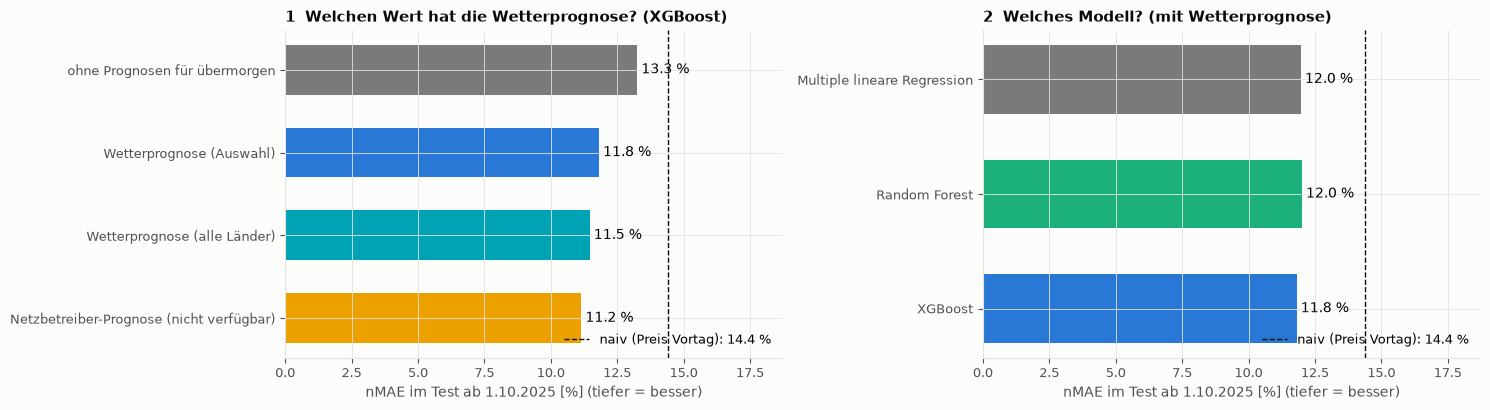

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

BASE = [c for c in dp.KEEP if "(D+2)" not in c]
WX = [c for c in dp.KEEP if "(D+2)" in c]
WX_ALL = dp.GROUPS["Wetter CH (D+2)"][:3] + dp.GROUPS["Wetter Ausland (D+2)"]
tso = dp.tso_features(hourly)
TSO = [c for c in tso if c.startswith("Residuallast")] + ["PV CH TSO", "Wind DE TSO"]
TEST_START = pd.Timestamp("2025-10-01", tz=dp.TZ).tz_convert("UTC")

forecasts = candidates[WX_ALL].join(tso[TSO])
delta = (forecasts - forecasts.shift(24)).add_prefix("Δ ")
data = candidates[BASE + [dp.TARGET]].join(forecasts).join(delta).loc["2024-02-18":].dropna()
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
y_train = train[dp.TARGET] - train["CH Lag 24h"]
scale = test[dp.TARGET].abs().mean()


def with_delta(cols):
    return cols + [f"Δ {c}" for c in cols]


def xgb():
    return XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5, min_child_weight=50, reg_lambda=10,
                        subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=-1)


def fit_score(model, cols):
    pred = test["CH Lag 24h"] + model.fit(train[cols], y_train).predict(test[cols])
    return 100 * np.abs(pred - test[dp.TARGET]).mean() / scale


naive = 100 * np.abs(test["CH Lag 24h"] - test[dp.TARGET]).mean() / scale
variants = pd.Series({
    "ohne Prognosen für übermorgen": fit_score(xgb(), BASE),
    "Wetterprognose (Auswahl)": fit_score(xgb(), BASE + with_delta(WX)),
    "Wetterprognose (alle Länder)": fit_score(xgb(), BASE + with_delta(WX_ALL)),
    "Netzbetreiber-Prognose (nicht verfügbar)": fit_score(xgb(), BASE + with_delta(TSO)),
})
models = pd.Series({
    "Multiple lineare Regression": fit_score(LinearRegression(), BASE + with_delta(WX)),
    "Random Forest": fit_score(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                                     random_state=0), BASE + with_delta(WX)),
    "XGBoost": variants["Wetterprognose (Auswahl)"],
})
print(f"Training {len(train):,} h, Test {len(test):,} h; naive Prognose (Preis Vortag): {naive:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, res, title, colors in (
        (axes[0], variants, "1  Welchen Wert hat die Wetterprognose? (XGBoost)",
         [COLORS[8], COLORS[0], COLORS[9], COLORS[3]]),
        (axes[1], models, "2  Welches Modell? (mit Wetterprognose)", [COLORS[8], COLORS[2], COLORS[0]])):
    ax.barh(res.index, res, color=colors, height=0.6)
    ax.axvline(naive, color=INK, linestyle="--", linewidth=1, label=f"naiv (Preis Vortag): {naive:.1f} %")
    ax.legend(loc="lower right")
    for i, v in enumerate(res):
        ax.text(v, i, f" {v:.1f} %", va="center", fontsize=10)
    ax.invert_yaxis()
    ax.set_xlabel("nMAE im Test ab 1.10.2025 [%] (tiefer = besser)")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, max(naive, res.max()) * 1.3)
save(fig, "06_vorabtest.png")
pd.concat({"Prognosen": variants, "Modell": models}).rename("nMAE [%]").to_frame().round(2)

**Was wir sehen:**
- Schon **ohne** Prognosen für übermorgen schlägt XGBoost die naive Prognose (Lags, Kalender,
  Füllstand und Gas reichen dafür).
- Die **Wetterprognose** senkt den Fehler deutlich und holt den grössten Teil dessen, was die
  Netzbetreiber-Prognose bringen würde. Mit allen Ländern ist der Fehler noch etwas tiefer als mit
  der Auswahl; welche Wetterreihen sich lohnen, prüft `03_modeling` (z. B. Wind FR).
- Die **Netzbetreiber-Prognose** wäre nochmals etwas besser, ist für übermorgen aber nicht verfügbar.
  Ein Modell damit sähe um diesen Abstand besser aus, als es im Einsatz wäre.
- **Modell:** XGBoost liegt knapp vor Random Forest und linearer Regression (11.8 % gegen je 12.0 %).
  Die lineare Regression ist hier nur so gut, weil das Ziel die Änderung zum Vortag ist und die
  Lags das Niveau schon liefern. Ungetunt sind die Abstände klein; das Tuning in `03_modeling`
  entscheidet endgültig.